In [1]:
from google.colab import drive
drive.mount('/content/drive')

import io, json, os, random, hashlib, re, time, gc, subprocess
from collections import Counter
from itertools import combinations
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import matplotlib.pyplot as plt
import requests
from PIL import Image, ImageOps
from tqdm import tqdm

# ----- the numbers of the guide -----
KB_SIZE, VALIDATION_SIZE = 10000, 100
TEST_PER_SCENE = {'simple': 34, 'medium': 33, 'complex': 33}     # test set = 100 images, stratified by scene complexity
TEST_SIZE = sum(TEST_PER_SCENE.values())
SEED = 42                                                        # same seed = same random choice every time

# ----- folders (everything is saved in Drive) -----
BASE = '/content/drive/MyDrive/RAG-Phase1'
FOLDER = {'train_kb': 'images/train', 'validation': 'images/validation', 'test': 'images/test'}
for folder in [*FOLDER.values(), 'plots', 'embeddings', 'index', 'metadata']:
    os.makedirs(f'{BASE}/{folder}', exist_ok=True)

ANN = '/content/annotations'      # COCO annotation files (they live in /content, so they are lost when Colab restarts)


def get_annotations():
    """Download the COCO annotations only when they are needed (about 1 minute)."""
    if os.path.exists(f'{ANN}/instances_train2017.json'):
        return
    url = 'http://images.cocodataset.org/annotations/annotations_trainval2017.zip'
    subprocess.run(['wget', '-nc', '-q', url, '-P', '/content'], check=True)
    subprocess.run(['unzip', '-n', '-q', '/content/annotations_trainval2017.zip', '-d', '/content'], check=True)


def load_json(path):
    with open(path) as f:
        return json.load(f)


def save_json(data, path):
    with open(path, 'w') as f:
        json.dump(data, f)


def clean_text(text):
    """For retrieval only: lowercase + no punctuation. The original caption is never changed."""
    return re.sub(r'[^a-z0-9 ]', '', text.lower()).strip()


def scene_type(number_of_objects):
    """simple = 0-2 objects, medium = 3-5, complex = 6 or more."""
    if number_of_objects <= 2:
        return 'simple'
    if number_of_objects <= 5:
        return 'medium'
    return 'complex'


def load_splits():
    """Load what Part 1 saved: the 3 lists of image ids + the 5 captions of each image."""
    splits = load_json(f'{BASE}/splits.json')
    captions = {int(k): v for k, v in load_json(f'{BASE}/captions.json').items()}
    return splits, captions


def require(*names):
    """Stop with a clear message if a variable is missing (this happens after a Colab restart)."""
    missing = [n for n in names if n not in globals()]
    if missing:
        raise RuntimeError(f'Missing: {missing}. Colab was restarted or a cell was skipped. '
                           'Run Setup, then the FIRST cell of this Part, then continue in order.')


print('Setup done. Part 1 already finished on Drive:', os.path.exists(f'{BASE}/splits.json'))

Mounted at /content/drive
Setup done. Part 1 already finished on Drive: True


## Part 1: Data audit, cleaning and splits


In [2]:
# 1.1) Functions of Part 1 (nothing runs here, it only defines them)
def group_captions(data):
    """{image id: [its captions]} and {image id: download link}."""
    captions = {}
    for a in data['annotations']:
        captions.setdefault(a['image_id'], []).append(a['caption'].strip())
    urls = {img['id']: img['coco_url'] for img in data['images']}
    return captions, urls


def download(ids, urls, folder, workers=16):
    """Download many images at the same time. Images that are already on disk are skipped."""
    def fetch(i):
        path = f'{folder}/{i:012d}.jpg'
        if os.path.exists(path):
            return
        for attempt in range(3):
            try:
                response = requests.get(urls[i], timeout=30)
                if response.status_code == 200:
                    with open(path + '.part', 'wb') as f:          # write to a temporary name first,
                        f.write(response.content)
                    os.replace(path + '.part', path)               # so an interrupted download never leaves a half image
                    return
            except (requests.RequestException, OSError):
                time.sleep(1)

    with ThreadPoolExecutor(workers) as pool:
        list(tqdm(pool.map(fetch, ids), total=len(ids)))


def inspect_image(path):
    """Returns ('missing' | 'corrupted' | 'ok', fingerprint). The file is read only once."""
    if not os.path.exists(path):
        return 'missing', None
    with open(path, 'rb') as f:
        data = f.read()
    try:
        Image.open(io.BytesIO(data)).verify()
    except Exception:
        return 'corrupted', None
    return 'ok', hashlib.md5(data).hexdigest()           # same file = same fingerprint


def build_clean_set(ids, urls, spare, folder, already_used=()):
    """Download + audit one set. Removes missing, corrupted and duplicate images (keeps the first copy)
    and replaces them with spares so the set stays full.
    Gives back: ids of the good images, their fingerprints, and how many images were removed.
    already_used = fingerprints of the earlier sets: the same picture can never be in two sets."""
    target = len(ids)
    kept, fingerprints, seen = [], set(), set(already_used)
    removed = {'missing': 0, 'corrupted': 0, 'duplicate': 0}
    todo = list(ids)
    while todo:
        download(todo, urls, folder)
        paths = [f'{folder}/{i:012d}.jpg' for i in todo]
        with ThreadPoolExecutor(16) as pool:
            results = list(pool.map(inspect_image, paths))
        for i, path, (status, fingerprint) in zip(todo, paths, results):
            if status == 'missing':
                removed['missing'] += 1
            elif status == 'corrupted':
                os.remove(path)
                removed['corrupted'] += 1
            elif fingerprint in seen:                          # duplicate (in this set or in an earlier set)
                os.remove(path)
                removed['duplicate'] += 1
            else:
                seen.add(fingerprint)
                fingerprints.add(fingerprint)
                kept.append(i)
        need = target - len(kept)
        if need > len(spare):
            raise RuntimeError('Not enough spare images left. Is the internet connection working?')
        todo = [spare.pop() for _ in range(need)]              # replacements (empty list = finished)
    print(folder.split('/')[-1], '-> kept', len(kept), '| removed', removed)
    return kept, fingerprints, removed

In [3]:
# 1.2) Run Part 1
def build_part1():
    get_annotations()

    # 1) Captions of every image
    train_captions, train_urls = group_captions(load_json(f'{ANN}/captions_train2017.json'))
    val_captions, val_urls = group_captions(load_json(f'{ANN}/captions_val2017.json'))

    # 2) KB + validation: random train2017 images with exactly 5 captions. The others are "spares".
    rng = random.Random(SEED)
    train_ok = sorted(i for i, c in train_captions.items() if len(c) == 5)
    rng.shuffle(train_ok)
    kb_ids = train_ok[:KB_SIZE]
    validation_ids = train_ok[KB_SIZE:KB_SIZE + VALIDATION_SIZE]
    train_spare = train_ok[KB_SIZE + VALIDATION_SIZE:]

    # 3) Test: val2017 images, stratified by scene complexity (= number of objects). Spares are kept per scene type,
    #    so a replacement never breaks the 34 / 33 / 33 balance.
    val_instances = load_json(f'{ANN}/instances_val2017.json')
    objects_in_image = Counter(a['image_id'] for a in val_instances['annotations'])
    del val_instances
    scenes = {'simple': [], 'medium': [], 'complex': []}
    for i in sorted(val_captions):
        if len(val_captions[i]) == 5 and objects_in_image[i] > 0:
            scenes[scene_type(objects_in_image[i])].append(i)
    test_picked, test_spare = {}, {}
    for scene, how_many in TEST_PER_SCENE.items():
        rng.shuffle(scenes[scene])
        test_picked[scene] = scenes[scene][:how_many]
        test_spare[scene] = scenes[scene][how_many:]
    print('Picked:', len(kb_ids), 'KB |', len(validation_ids), 'validation |', sum(map(len, test_picked.values())), 'test')

    # 4) Download + audit
    kb_ids, kb_fp, kb_removed = build_clean_set(kb_ids, train_urls, train_spare, f'{BASE}/{FOLDER["train_kb"]}')
    validation_ids, val_fp, val_removed = build_clean_set(validation_ids, train_urls, train_spare,
                                                          f'{BASE}/{FOLDER["validation"]}', kb_fp)
    test_ids, test_fp = [], set()
    test_removed = {'missing': 0, 'corrupted': 0, 'duplicate': 0}
    for scene in TEST_PER_SCENE:
        kept, fp, removed = build_clean_set(test_picked[scene], val_urls, test_spare[scene],
                                            f'{BASE}/{FOLDER["test"]}', kb_fp | val_fp | test_fp)
        test_ids += kept
        test_fp |= fp
        test_removed = {k: test_removed[k] + removed[k] for k in test_removed}

    # 5) Checks + leakage audit (the code stops with an error if something is wrong)
    sets = {'train_kb': kb_ids, 'validation': validation_ids, 'test': test_ids}
    fingerprints = {'train_kb': kb_fp, 'validation': val_fp, 'test': test_fp}
    expected = {'train_kb': KB_SIZE, 'validation': VALIDATION_SIZE, 'test': TEST_SIZE}
    captions = {}
    for name, ids in sets.items():
        folder = f'{BASE}/{FOLDER[name]}'
        wanted = {f'{i:012d}.jpg' for i in ids}
        for f in os.listdir(folder):                           # remove leftovers of earlier runs
            if f not in wanted and f.endswith(('.jpg', '.part')):
                os.remove(f'{folder}/{f}')
        source = val_captions if name == 'test' else train_captions
        for i in ids:
            captions[i] = source[i]
        assert len(ids) == expected[name] and len(set(ids)) == len(ids), f'{name}: wrong number of ids'
        jpgs = [f for f in os.listdir(folder) if f.endswith('.jpg')]
        assert len(jpgs) == len(ids), f'{name}: image files and ids do not match'
    assert all(len(c) == 5 and all(t.strip() for t in c) for c in captions.values()), 'an image has not 5 good captions'

    audit = {}
    for a, b in combinations(sets, 2):                         # no image may be in two sets
        shared_ids = set(sets[a]) & set(sets[b])
        shared_pictures = fingerprints[a] & fingerprints[b]
        audit[f'{a}_vs_{b}'] = {'shared_ids': len(shared_ids), 'shared_pictures': len(shared_pictures)}
        assert not shared_ids and not shared_pictures, f'LEAKAGE between {a} and {b}'
    print('All checks passed. Leakage audit:', audit)

    # 6) Save: frozen split ids, raw captions, audit, cleaning report, fingerprints
    save_json(captions, f'{BASE}/captions.json')
    save_json(audit, f'{BASE}/metadata/leakage_audit.json')
    save_json({'train_kb': kb_removed, 'validation': val_removed, 'test': test_removed},
              f'{BASE}/metadata/cleaning_report.json')
    save_json({name: sorted(fp) for name, fp in fingerprints.items()}, f'{BASE}/metadata/fingerprints.json')
    save_json(sets, f'{BASE}/splits.json')                     # saved LAST: if it exists, Part 1 really finished


if os.path.exists(f'{BASE}/splits.json'):
    print('Part 1 is already done (splits.json exists on Drive). Nothing to download.')
    print('To redo it from zero, delete splits.json from the RAG-Phase1 folder in Drive.\n')
    splits, _ = load_splits()
    for name, ids in splits.items():
        on_disk = len([f for f in os.listdir(f'{BASE}/{FOLDER[name]}') if f.endswith('.jpg')])
        print(f'{name:<11}: {len(ids)} ids | {on_disk} images on Drive', '(OK)' if on_disk == len(ids) else '(MISMATCH!)')
else:
    build_part1()

Part 1 is already done (splits.json exists on Drive). Nothing to download.
To redo it from zero, delete splits.json from the RAG-Phase1 folder in Drive.

train_kb   : 10000 ids | 10000 images on Drive (OK)
validation : 100 ids | 100 images on Drive (OK)
test       : 100 ids | 100 images on Drive (OK)


## Part 2: Statistical exploration + metadata



In [4]:
# 2.1) Load splits, objects of every image, basic statistics
splits, captions = load_splits()
kb_ids, validation_ids, test_ids = splits['train_kb'], splits['validation'], splits['test']

CACHE = f'{BASE}/metadata/objects_cache.json'


def read_objects(ids, annotation_file):
    """{image id: ['person', 'dog', ...]} for the given images, and {class: supercategory}."""
    data = load_json(annotation_file)
    name = {c['id']: c['name'] for c in data['categories']}
    group = {c['name']: c['supercategory'] for c in data['categories']}
    found = {i: [] for i in ids}
    for a in data['annotations']:
        if a['image_id'] in found:
            found[a['image_id']].append(name[a['category_id']])
    del data
    gc.collect()                                              # the annotation file is huge: free the memory
    return found, group


if os.path.exists(CACHE):
    cache = load_json(CACHE)
    group_of = cache['group_of']
    all_objects = {int(k): v for k, v in cache['objects'].items()}
    print('Objects loaded from the cache on Drive (the big annotation file is not needed)')
else:
    get_annotations()
    train_found, group_of = read_objects(kb_ids + validation_ids, f'{ANN}/instances_train2017.json')
    test_found, _ = read_objects(test_ids, f'{ANN}/instances_val2017.json')
    all_objects = {**train_found, **test_found}
    save_json({'group_of': group_of, 'objects': all_objects}, CACHE)

objects = {i: all_objects[i] for i in kb_ids}                 # metadata of the KB
eval_objects = {'validation': {i: all_objects[i] for i in validation_ids},     # EVALUATION ONLY (hallucination rate),
                'test': {i: all_objects[i] for i in test_ids}}                  # never use them for retrieval

class_counts, group_counts = Counter(), Counter()
for names in objects.values():
    for name in names:
        class_counts[name] += 1
        group_counts[group_of[name]] += 1

objects_per_image = [len(objects[i]) for i in kb_ids]
scene_counts = Counter(scene_type(n) for n in objects_per_image)
caption_lengths = [len(c.split()) for i in kb_ids for c in captions[i]]                      # words per caption
average_caption_length = [np.mean([len(c.split()) for c in captions[i]]) for i in kb_ids]    # per image

vocabulary = set()
for i in kb_ids:
    for c in captions[i]:
        vocabulary.update(clean_text(c).split())

print('Average objects per image  :', round(np.mean(objects_per_image), 2))
print('Images with no object      :', objects_per_image.count(0))
print('Scene types                :', dict(scene_counts))
print('Average caption length     :', round(np.mean(caption_lengths), 2), 'words')
print('Vocabulary size            :', len(vocabulary), 'different words')
print('Different object categories:', len(class_counts))

Average objects per image  : 7.19
Images with no object      : 90
Scene types                : {'complex': 4251, 'simple': 3046, 'medium': 2703}
Average caption length     : 10.45 words
Vocabulary size            : 10080 different words
Different object categories: 80


In [5]:
# 2.2) Per-image attributes from the caption words + part-of-speech distribution
require('kb_ids', 'captions', 'objects')
import nltk
for package in ['averaged_perceptron_tagger', 'averaged_perceptron_tagger_eng']:
    nltk.download(package, quiet=True)

# COCO does not give colours, shapes, context or relations, so we estimate them from the words of the 5 captions.
WORDS = {
    'colours': {c: [c] for c in ['white', 'black', 'red', 'blue', 'green', 'yellow', 'brown', 'orange', 'pink', 'purple', 'gray', 'grey']},
    'shapes_sizes': {s: [s] for s in ['round', 'square', 'rectangular', 'circular', 'long', 'tall', 'flat', 'small', 'big', 'large']},
    'context': {'indoor': ['kitchen', 'bathroom', 'bedroom', 'room', 'indoor', 'indoors', 'inside', 'office'],
                'outdoor': ['street', 'beach', 'field', 'park', 'road', 'outside', 'outdoor', 'grass', 'snow', 'city'],
                'day': ['sunny', 'daytime', 'day'],
                'night': ['night', 'dark', 'evening']},
    'spatial_relations': {'next to': ['next to', 'beside'], 'behind': ['behind'], 'under': ['under', 'beneath', 'below'],
                          'above': ['above', 'over'], 'in front of': ['in front of'], 'near': ['near', 'close to'],
                          'between': ['between'], 'on top of': ['on top of']},
}


def find_labels(text, word_groups):
    """Which labels appear in the text? (spaces around each word = whole words only)"""
    return [label for label, words in word_groups.items() if any(f' {w} ' in text for w in words)]


texts = {i: ' ' + ' '.join(clean_text(c) for c in captions[i]) + ' ' for i in kb_ids}
attributes = {i: {kind: find_labels(texts[i], groups) for kind, groups in WORDS.items()} for i in kb_ids}

diversity = {kind: Counter() for kind in WORDS}               # how many images have each label
for i in kb_ids:
    for kind, labels in attributes[i].items():
        diversity[kind].update(labels)


def coarse_pos(tag):
    """Group the detailed tags (NN, NNS, NNP ...) into readable classes."""
    if tag.startswith('NN'):
        return 'noun'
    if tag.startswith('VB'):
        return 'verb'
    if tag.startswith('JJ'):
        return 'adjective'
    if tag.startswith('RB'):
        return 'adverb'
    return {'IN': 'preposition', 'DT': 'determiner', 'CC': 'conjunction', 'CD': 'number',
            'PRP': 'pronoun', 'PRP$': 'pronoun'}.get(tag, 'other')


all_captions = [c for i in kb_ids for c in captions[i]]
pos_counts = Counter()
for c in random.Random(SEED).sample(all_captions, min(5000, len(all_captions))):
    for word, tag in nltk.pos_tag(clean_text(c).split()):
        pos_counts[coarse_pos(tag)] += 1

print('Context :', dict(diversity['context']))
print('POS     :', dict(pos_counts.most_common()))
print('Example :', kb_ids[0], attributes[kb_ids[0]])

Context : {'indoor': 1663, 'day': 404, 'outdoor': 3737, 'night': 267}
POS     : {'noun': 18550, 'determiner': 10740, 'preposition': 8430, 'verb': 6108, 'adjective': 4145, 'other': 1323, 'conjunction': 1202, 'pronoun': 712, 'number': 676, 'adverb': 314}
Example : 228867 {'colours': [], 'shapes_sizes': [], 'context': ['indoor'], 'spatial_relations': []}


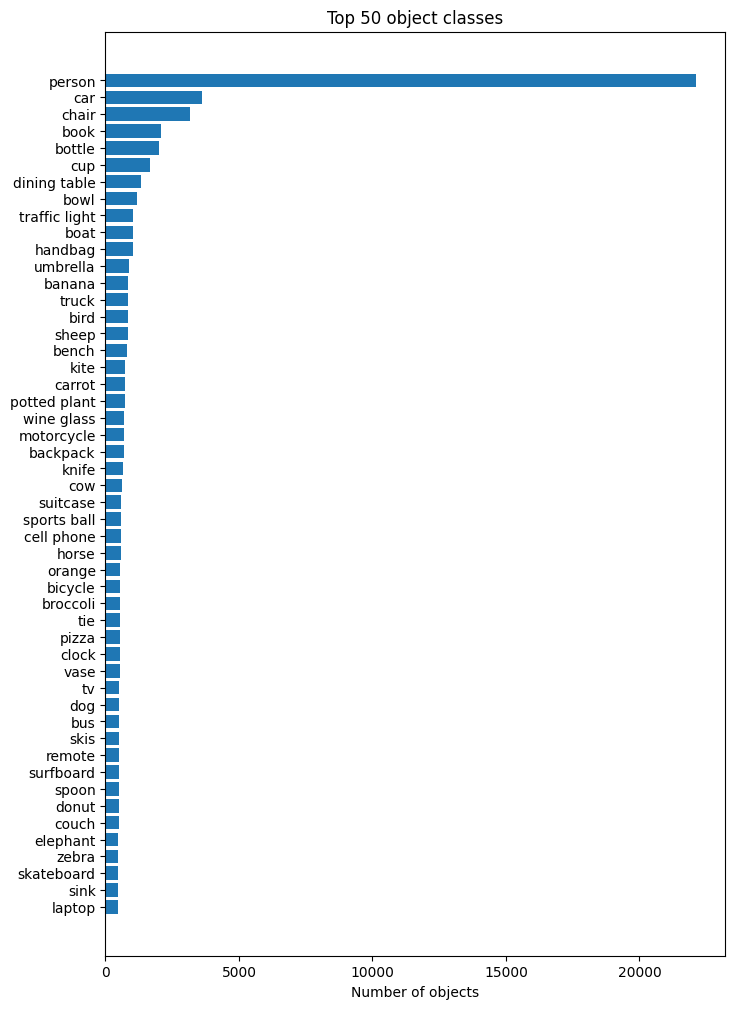

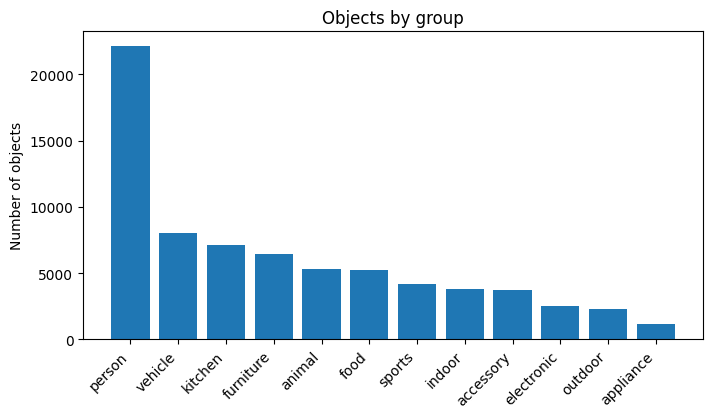

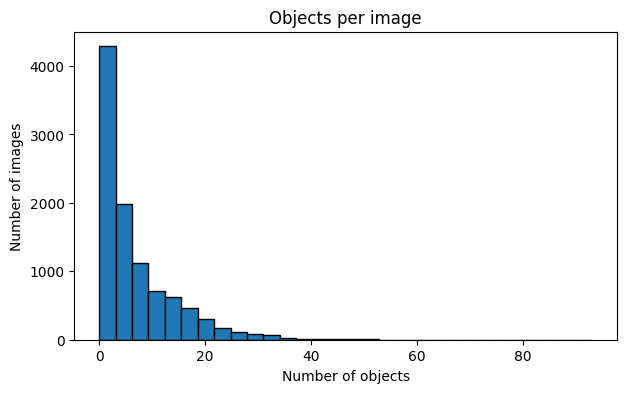

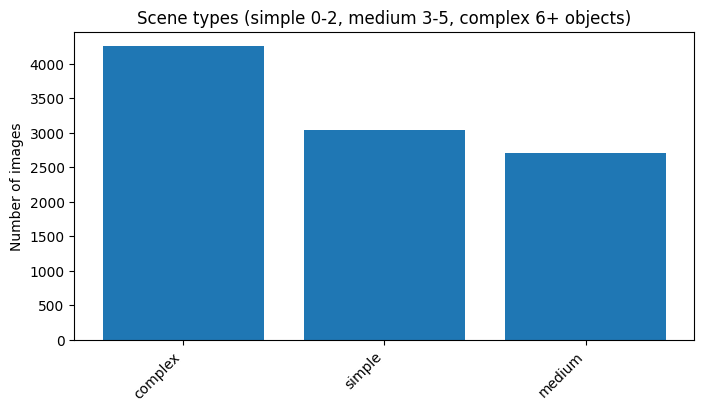

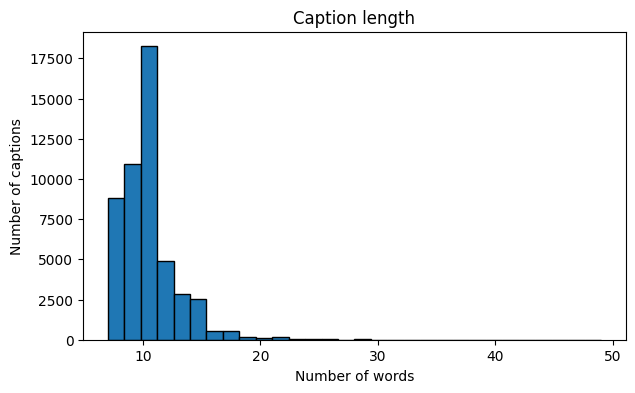

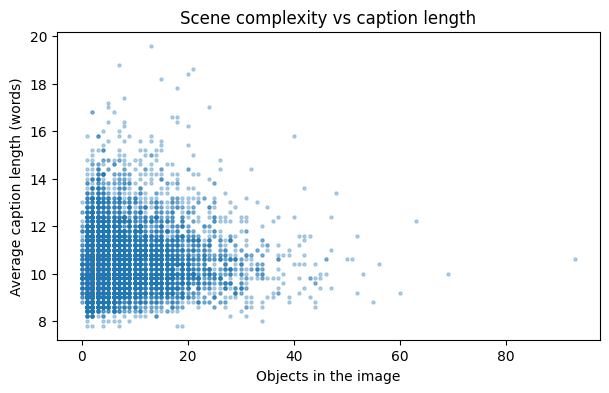

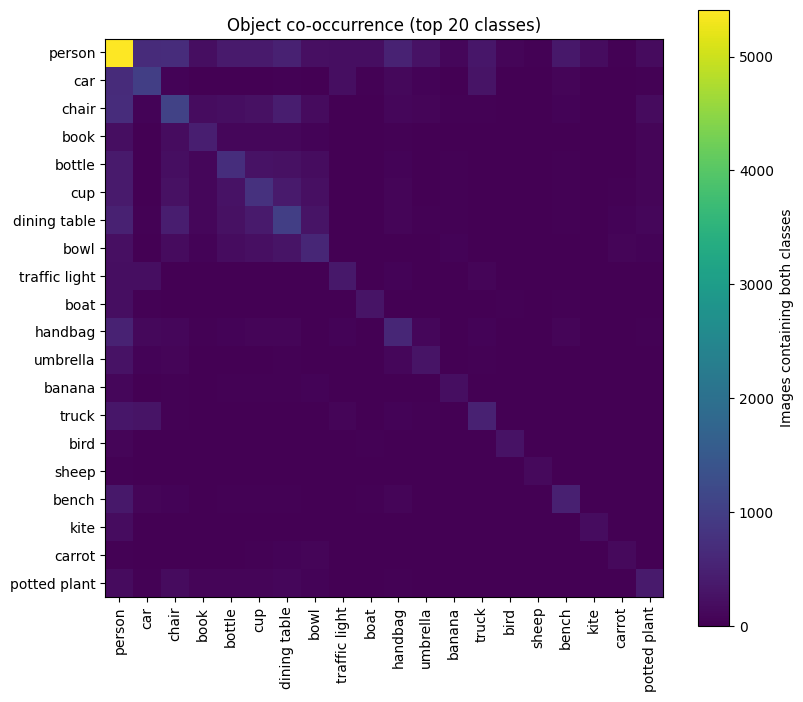

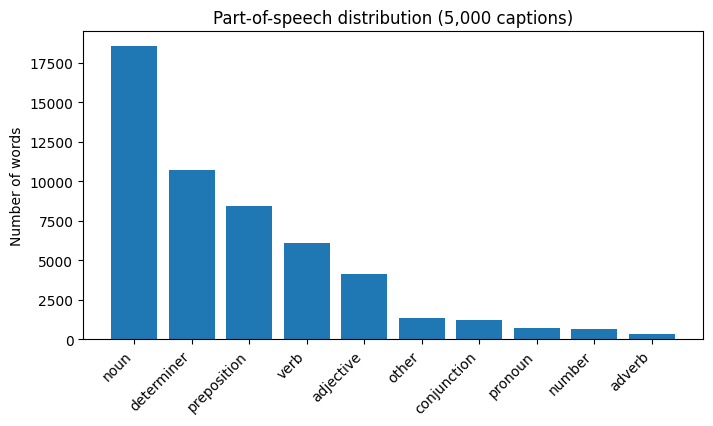

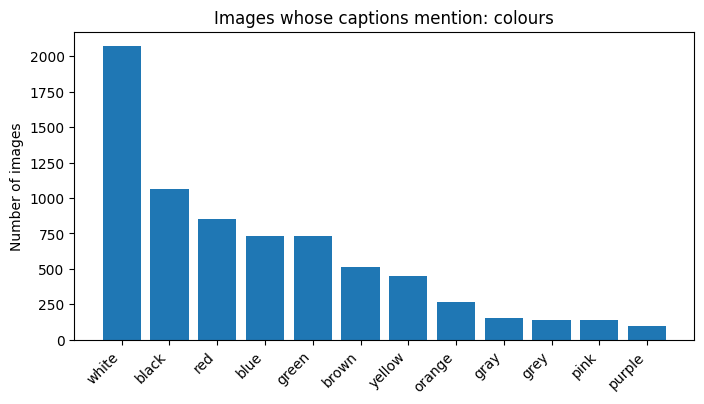

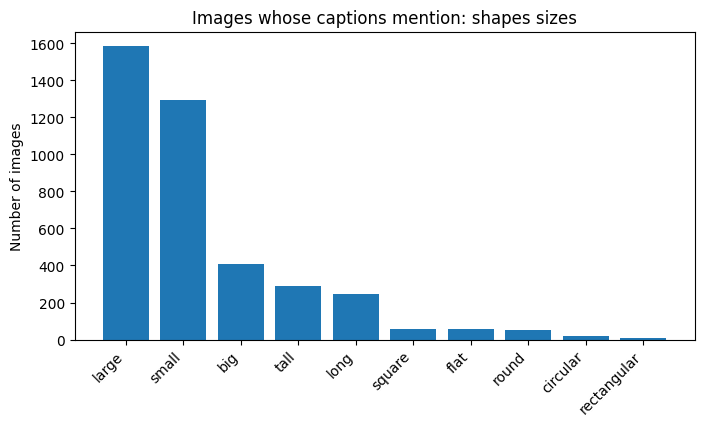

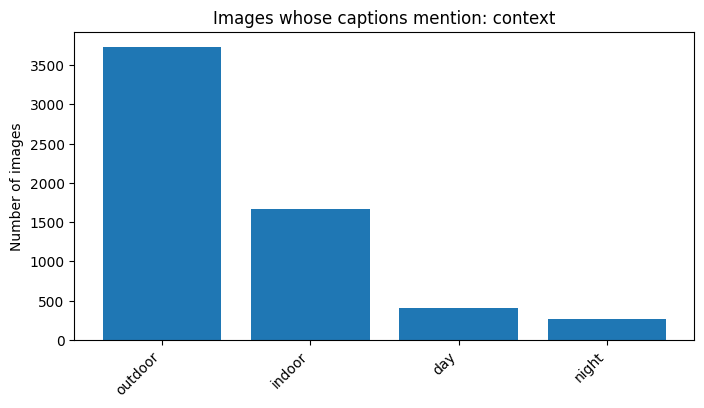

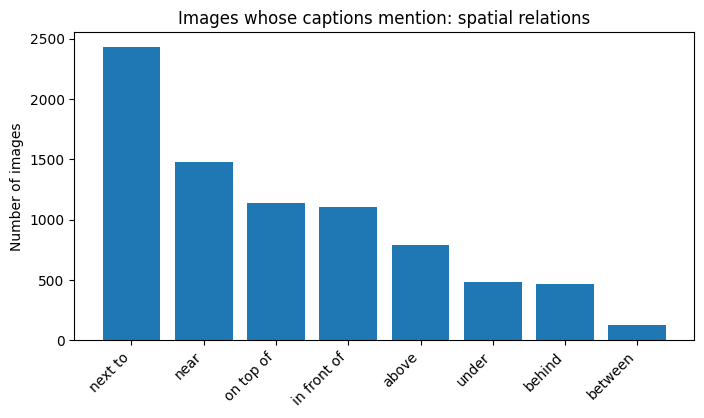

In [6]:
# 2.3) All the plots (saved in Drive/RAG-Phase1/plots)
require('class_counts', 'group_counts', 'objects_per_image', 'diversity', 'pos_counts')


def show(title, xlabel, ylabel, filename):
    """Add the labels, save the plot in Drive and display it."""
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.savefig(f'{BASE}/plots/{filename}', bbox_inches='tight')
    plt.show()
    plt.close()


def bar_plot(counts, title, ylabel, filename):
    labels = [label for label, n in counts.most_common()]
    plt.figure(figsize=(8, 4))
    plt.bar(labels, [counts[label] for label in labels])
    plt.xticks(rotation=45, ha='right')
    show(title, '', ylabel, filename)


# 1) Distribution of object classes: the 50 most frequent
top = class_counts.most_common(50)[::-1]
plt.figure(figsize=(8, 12))
plt.barh([name for name, n in top], [n for name, n in top])
show('Top 50 object classes', 'Number of objects', '', 'top_50_classes.png')

# 2) The same, grouped (person, animal, vehicle, ...)
bar_plot(group_counts, 'Objects by group', 'Number of objects', 'groups.png')

# 3) Scene complexity = number of objects per image
plt.figure(figsize=(7, 4))
plt.hist(objects_per_image, bins=30, edgecolor='black')
show('Objects per image', 'Number of objects', 'Number of images', 'objects_per_image.png')
bar_plot(scene_counts, 'Scene types (simple 0-2, medium 3-5, complex 6+ objects)', 'Number of images', 'scene_types.png')

# 4) Caption length
plt.figure(figsize=(7, 4))
plt.hist(caption_lengths, bins=30, edgecolor='black')
show('Caption length', 'Number of words', 'Number of captions', 'caption_length.png')

# 5) Do crowded scenes get longer captions?
plt.figure(figsize=(7, 4))
plt.scatter(objects_per_image, average_caption_length, s=5, alpha=0.3)
show('Scene complexity vs caption length', 'Objects in the image', 'Average caption length (words)', 'complexity_vs_length.png')

# 6) Co-occurrence matrix: how many images contain both class i and class j (top 20 classes)
top20 = [name for name, n in class_counts.most_common(20)]
position = {name: k for k, name in enumerate(top20)}
matrix = np.zeros((len(top20), len(top20)), dtype=int)
for names in objects.values():
    present = [position[n] for n in set(names) if n in position]
    for a in present:
        for b in present:
            matrix[a, b] += 1
plt.figure(figsize=(9, 8))
plt.imshow(matrix)
plt.colorbar(label='Images containing both classes')
plt.xticks(range(len(top20)), top20, rotation=90)
plt.yticks(range(len(top20)), top20)
show('Object co-occurrence (top 20 classes)', '', '', 'cooccurrence.png')

# 7) Part-of-speech distribution
bar_plot(pos_counts, 'Part-of-speech distribution (5,000 captions)', 'Number of words', 'pos_distribution.png')

# 8) Diversity: colours, shapes, context, spatial relations
for kind, counts in diversity.items():
    bar_plot(counts, f'Images whose captions mention: {kind.replace("_", " ")}', 'Number of images', f'diversity_{kind}.png')

In [7]:
# 2.4) Save the metadata (linked to the image ids) and all the numbers
require('objects', 'attributes', 'diversity', 'pos_counts', 'eval_objects')

# one record per KB image. vector_row = row of this image in the image embeddings (Part 3)
records = [{'image_id': i, 'vector_row': row, 'captions': captions[i],
            'objects': objects[i], 'object_counts': dict(Counter(objects[i])),
            'scene_type': scene_type(len(objects[i])), **attributes[i]}
           for row, i in enumerate(kb_ids)]
save_json(records, f'{BASE}/metadata/kb_records.json')
save_json(objects, f'{BASE}/metadata/objects.json')
save_json(eval_objects, f'{BASE}/metadata/eval_objects.json')   # EVALUATION ONLY (hallucination rate)

save_json({'average_objects_per_image': float(np.mean(objects_per_image)),
           'images_without_objects': objects_per_image.count(0),
           'scene_types': dict(scene_counts),
           'average_caption_length': float(np.mean(caption_lengths)),
           'vocabulary_size': len(vocabulary),
           'top_50_classes': class_counts.most_common(50),
           'groups': dict(group_counts),
           'pos': dict(pos_counts),
           'diversity': {kind: dict(c) for kind, c in diversity.items()}}, f'{BASE}/metadata/statistics.json')
print('Saved:', len(records), 'KB records. Part 2 done.')

Saved: 10000 KB records. Part 2 done.


## Part 3: Embeddings, FAISS index, documentation



In [8]:
# 3.1) Load CLIP and define the embedding functions
!pip install -q faiss-cpu

import faiss
import torch
import transformers
from torch.utils.data import Dataset, DataLoader
from transformers import CLIPModel, CLIPProcessor

splits, captions = load_splits()
kb_ids, validation_ids, test_ids = splits['train_kb'], splits['validation'], splits['test']

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Using:', device)
if device == 'cpu':
    print('WARNING: no GPU. This will take very long. Runtime > Change runtime type > T4 GPU (then run Setup again).')
MODEL = 'openai/clip-vit-base-patch32'
IMAGE_BATCH, TEXT_BATCH = 64, 256
model = CLIPModel.from_pretrained(MODEL).to(device).eval()
processor = CLIPProcessor.from_pretrained(MODEL)
EMBED_DIM = model.config.projection_dim                        # 512 for this model


def to_unit_vectors(features):
    """Make every vector have length 1."""
    if not torch.is_tensor(features):                          # some library versions wrap the result
        features = features.pooler_output
    features = features.cpu().numpy()
    return (features / np.linalg.norm(features, axis=1, keepdims=True)).astype('float32')


class ImageFiles(Dataset):
    """Loads the images in the background while the GPU works."""
    def __init__(self, paths):
        self.paths = paths

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, k):
        # fix the rotation (EXIF), then 3 colour channels (RGB)
        return ImageOps.exif_transpose(Image.open(self.paths[k])).convert('RGB')


def collate(images):
    return processor(images=images, return_tensors='pt')       # the processor resizes + normalises for CLIP


def embed_images(ids, set_name):
    """Images -> vectors. Row k of the result = image ids[k]."""
    paths = [f'{BASE}/{FOLDER[set_name]}/{i:012d}.jpg' for i in ids]
    loader = DataLoader(ImageFiles(paths), batch_size=IMAGE_BATCH, num_workers=2, collate_fn=collate)   # no shuffle: order kept
    vectors = []
    for inputs in tqdm(loader):
        inputs = inputs.to(device)
        with torch.no_grad():
            vectors.append(to_unit_vectors(model.get_image_features(**inputs)))
    return np.concatenate(vectors)


def embed_texts(texts):
    """Captions -> vectors."""
    vectors = []
    for start in tqdm(range(0, len(texts), TEXT_BATCH)):
        inputs = processor(text=texts[start:start + TEXT_BATCH], padding=True, truncation=True,
                           return_tensors='pt').to(device)
        with torch.no_grad():
            vectors.append(to_unit_vectors(model.get_text_features(**inputs)))
    return np.concatenate(vectors)

Using: cpu


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

... (3 outputs left out)

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

In [9]:
# 3.2) Compute the vectors (or load them from Drive), check them, save them
require('model', 'processor', 'embed_images', 'embed_texts', 'kb_ids')


def check_vectors(name, vectors, expected_rows):
    """Quality control: right shape, no NaN (missing numbers), every length = 1."""
    assert vectors.shape == (expected_rows, EMBED_DIM), f'{name}: wrong shape {vectors.shape}'
    assert not np.isnan(vectors).any(), f'{name}: contains NaN'
    assert np.allclose(np.linalg.norm(vectors, axis=1), 1, atol=1e-3), f'{name}: length is not 1'


def cached_vectors(name, expected_rows, compute):
    """Load the vectors from Drive if they exist, otherwise compute, check and save them."""
    path = f'{BASE}/embeddings/{name}.npy'
    if os.path.exists(path):
        vectors = np.load(path)
        print(f'{name}: loaded from Drive')
    else:
        vectors = compute()
        check_vectors(name, vectors, expected_rows)            # a bad result is never saved
        np.save(path, vectors)
        print(f'{name}: computed and saved')
    check_vectors(name, vectors, expected_rows)
    return vectors



caption_rows = [{'image_id': i, 'caption_raw': c, 'caption_clean': clean_text(c)}
                for i in kb_ids for c in captions[i]]
assert all(row['caption_raw'] == c for row, c in zip(caption_rows, [c for i in kb_ids for c in captions[i]])), 'a raw caption was changed'
assert len(set(kb_ids)) == len(kb_ids), 'duplicate ids in the KB'

kb_image_vectors = cached_vectors('kb_image_vectors', KB_SIZE, lambda: embed_images(kb_ids, 'train_kb'))
validation_image_vectors = cached_vectors('validation_image_vectors', VALIDATION_SIZE, lambda: embed_images(validation_ids, 'validation'))
test_image_vectors = cached_vectors('test_image_vectors', TEST_SIZE, lambda: embed_images(test_ids, 'test'))
caption_vectors = cached_vectors('kb_caption_vectors', KB_SIZE * 5,
                                 lambda: embed_texts([row['caption_clean'] for row in caption_rows]))

# the ids files
np.save(f'{BASE}/embeddings/kb_image_ids.npy', np.array(kb_ids))
np.save(f'{BASE}/embeddings/validation_image_ids.npy', np.array(validation_ids))
np.save(f'{BASE}/embeddings/test_image_ids.npy', np.array(test_ids))
save_json(caption_rows, f'{BASE}/metadata/kb_caption_rows.json')

print('KB images   :', kb_image_vectors.shape)
print('KB captions :', caption_vectors.shape)
print('Validation  :', validation_image_vectors.shape, '| Test:', test_image_vectors.shape)
print('All embedding checks passed')

kb_image_vectors: loaded from Drive
validation_image_vectors: loaded from Drive
test_image_vectors: loaded from Drive
kb_caption_vectors: loaded from Drive
KB images   : (10000, 512)
KB captions : (50000, 512)
Validation  : (100, 512) | Test: (100, 512)
All embedding checks passed


{'type': 'IndexFlatIP (flat, exact search)', 'similarity': 'cosine (inner product, vectors of length 1)', 'vectors': 10000, 'dimension': 512, 'size_MB': 20.48, 'indexing_seconds': 0.02}
{'type': 'IndexFlatIP (flat, exact search)', 'similarity': 'cosine (inner product, vectors of length 1)', 'vectors': 50000, 'dimension': 512, 'size_MB': 102.4, 'indexing_seconds': 0.223}

Real captions of the test image: ['A man riding a kiteboard over the ocean under a gray sky.', 'A kite surfer gets high in the air while his kite is out of the picture frame.'] ...
Retrieved KB captions:
 - A man kiteboarding on top of the ocean.
 - A man kiteboarding over the ocean next to shore.
 - A parasailer holding on to the sail and waiting to land.
 - A person kiteboarding over the ocean on waves.
 - Someone in a wetsuit in the blue waters parasailing.


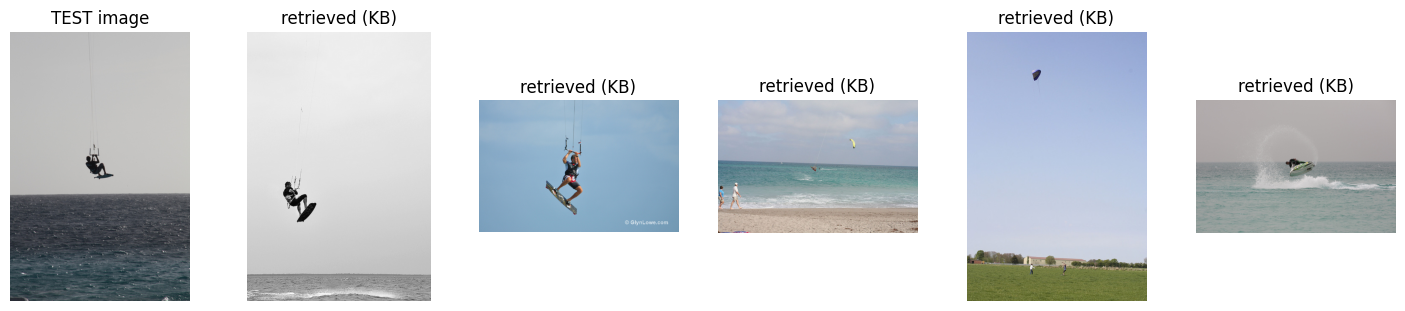

In [10]:
# 3.3) FAISS index (the vector database). Flat = exact search, inner product on unit vectors = cosine similarity.
require('kb_image_vectors', 'caption_vectors', 'caption_rows', 'test_image_vectors')


def build_index(vectors, name):
    start = time.time()
    index = faiss.IndexFlatIP(vectors.shape[1])
    index.add(vectors)
    seconds = time.time() - start
    path = f'{BASE}/index/{name}.faiss'
    faiss.write_index(index, path)
    info = {'type': 'IndexFlatIP (flat, exact search)', 'similarity': 'cosine (inner product, vectors of length 1)',
            'vectors': index.ntotal, 'dimension': vectors.shape[1],
            'size_MB': round(os.path.getsize(path) / 1e6, 2), 'indexing_seconds': round(seconds, 3)}
    return index, info


image_index, image_index_info = build_index(kb_image_vectors, 'kb_images')
caption_index, caption_index_info = build_index(caption_vectors, 'kb_captions')
print(image_index_info)
print(caption_index_info)

# Does retrieval work? One TEST image -> its 5 most similar KB captions and KB images
query = test_image_vectors[:1]
caption_rows_found = caption_index.search(query, 5)[1][0]
retrieved_images = [kb_ids[k] for k in image_index.search(query, 5)[1][0]]
assert not set(retrieved_images) & set(test_ids), 'a test image was retrieved for itself'

print('\nReal captions of the test image:', captions[test_ids[0]][:2], '...')
print('Retrieved KB captions:')
for k in caption_rows_found:
    print(' -', caption_rows[k]['caption_raw'])

fig, axes = plt.subplots(1, 6, figsize=(18, 3.5))
axes[0].imshow(Image.open(f'{BASE}/{FOLDER["test"]}/{test_ids[0]:012d}.jpg'))
axes[0].set_title('TEST image')
for ax, i in zip(axes[1:], retrieved_images):
    ax.imshow(Image.open(f'{BASE}/{FOLDER["train_kb"]}/{i:012d}.jpg'))
    ax.set_title('retrieved (KB)')
for ax in axes:
    ax.axis('off')
plt.show()

In [11]:
# 3.4) Documentation of Phase 1 (everything the guide asks to record)
require('image_index_info', 'caption_index_info', 'MODEL')
documentation = {
    'splits': {'train_kb': {'source': 'COCO train2017', 'size': len(kb_ids)},
               'validation': {'source': 'COCO train2017, different images from the KB', 'size': len(validation_ids)},
               'test': {'source': 'COCO val2017, stratified', 'size': len(test_ids), 'per_scene_type': TEST_PER_SCENE,
                        'scene_types': 'simple = 0-2 objects, medium = 3-5, complex = 6 or more'},
               'random_seed': SEED, 'split_ids_file': 'splits.json'},
    'audit': {'removed_images': load_json(f'{BASE}/metadata/cleaning_report.json'),
              'leakage_audit': load_json(f'{BASE}/metadata/leakage_audit.json')},
    'preprocessing': {
        'images': 'EXIF rotation fixed, converted to RGB, resized + normalised by the CLIP processor',
        'captions': 'caption_raw = original (evaluation), caption_clean = lowercase + no punctuation (retrieval only)',
        'metadata': 'objects and scene type from the COCO annotations (no detector used). Colours, shapes, context and '
                    'spatial relations are estimated from caption words because COCO does not provide them. '
                    'eval_objects.json (validation + test) is for evaluation only, never for retrieval'},
    'embeddings': {'model': MODEL, 'dimension': EMBED_DIM, 'image_batch_size': IMAGE_BATCH, 'text_batch_size': TEXT_BATCH,
                   'normalisation': 'every vector has length 1', 'format': '.npy'},
    'indexes': {'images': image_index_info, 'captions': caption_index_info},
    'versions': {'numpy': np.__version__, 'torch': torch.__version__, 'transformers': transformers.__version__,
                 'faiss': faiss.__version__, 'device': device},
}
save_json(documentation, f'{BASE}/metadata/phase1_documentation.json')
print(json.dumps(documentation, indent=2)[:1500])

{
  "splits": {
    "train_kb": {
      "source": "COCO train2017",
      "size": 10000
    },
    "validation": {
      "source": "COCO train2017, different images from the KB",
      "size": 100
    },
    "test": {
      "source": "COCO val2017, stratified",
      "size": 100,
      "per_scene_type": {
        "simple": 34,
        "medium": 33,
        "complex": 33
      },
      "scene_types": "simple = 0-2 objects, medium = 3-5, complex = 6 or more"
    },
    "random_seed": 42,
    "split_ids_file": "splits.json"
  },
  "audit": {
    "removed_images": {
      "train_kb": {
        "missing": 0,
        "corrupted": 0,
        "duplicate": 0
      },
      "validation": {
        "missing": 0,
        "corrupted": 0,
        "duplicate": 0
      },
      "test": {
        "missing": 0,
        "corrupted": 0,
        "duplicate": 0
      }
    },
    "leakage_audit": {
      "train_kb_vs_validation": {
        "shared_ids": 0,
        "shared_pictures": 0
      },
      "train_